# Closing the loop: a recursive attitude filter

The previous notebook solved attitude determination as a single instant's problem: given the measurements available right now, what is the best estimate of attitude. A real spacecraft does not get to start from scratch every time; it has a gyro giving a continuous (biased, noisy) rate, and it has memory of where it was a moment ago. This notebook combines the two pieces already built, the rigid body kinematics from `attitude_pointing_control.ipynb` and the vector-measurement attitude solutions from `attitude_determination.ipynb`, into a multiplicative extended Kalman filter (MEKF): a recursive estimator that propagates attitude continuously from gyro data and corrects it, and the gyro's own bias, whenever a new vector measurement arrives.

The headline result this notebook validates: left alone, gyro-only integration (dead reckoning) drifts away from the truth as its unknown bias accumulates error; the filter, given the exact same noisy gyro and the exact same noisy vector measurements, does not.

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from ios_mission_planner.dynamics.attitude.rigid_body import rigid_body_attitude_dynamics_symbolic
from ios_mission_planner.dynamics.attitude.determination import (
    quaternion_to_rotation_matrix, rotation_matrix_to_quaternion, wahba_svd_attitude,
)
from ios_mission_planner.dynamics.attitude.filter import MEKFState, mekf_predict, mekf_update
from ios_mission_planner.propagation.heyoka_propagator import propagate

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

COL_ANA = "#1f77b4"
COL_NUM = "#d62728"
COL_ZONE = "#9467bd"

## The scenario

A tumbling rigid body (the same kind of asymmetric-inertia tumble from `attitude_pointing_control.ipynb`'s torque-free case), a gyro reading its true body rate plus a constant, unknown bias and white noise, and a vector-measurement update (the same `wahba_svd_attitude` from the previous notebook, with its own injected noise) arriving every two seconds. Two filters run side by side on the identical simulated data: the MEKF, and a "dead reckoning" filter that only ever integrates the raw gyro reading, never correcting for bias.

In [2]:
rng = np.random.default_rng(42)
ix, iy, iz = 10.0, 15.0, 20.0
state0 = np.array([1.0, 0.0, 0.0, 0.0, 0.05, 0.03, 0.3])

dt = 0.1
t_total = 300.0
n_steps = int(t_total / dt)
t_eval = np.linspace(0.0, t_total, n_steps + 1)
true_sol = propagate(rigid_body_attitude_dynamics_symbolic(), state0, t_eval, pars=[ix, iy, iz, 0.0, 0.0, 0.0]).y

true_bias = np.array([0.002, -0.001, 0.0015])  # rad/s, constant and unknown to both filters
gyro_noise_std = 0.0005
meas_noise_deg = 0.5
update_every = 20  # every 2 s

r_vectors_ref = rng.normal(size=(6, 3))
r_vectors_ref /= np.linalg.norm(r_vectors_ref, axis=1, keepdims=True)
measurement_cov = np.eye(3) * np.deg2rad(meas_noise_deg) ** 2

filt = MEKFState(q=np.array([1.0, 0.0, 0.0, 0.0]), bias=np.zeros(3),
                 covariance=np.diag([np.deg2rad(5.0) ** 2] * 3 + [0.01 ** 2] * 3))
dead = MEKFState(q=np.array([1.0, 0.0, 0.0, 0.0]), bias=np.zeros(3), covariance=np.eye(6))

err_filt, err_dead, bias_hist = [], [], []

def angular_error_deg(q_a, q_b):
    return 2 * np.degrees(np.arccos(np.clip(abs(q_a @ q_b), 0.0, 1.0)))

for k in range(n_steps):
    gyro_meas = true_sol[4:7, k] + true_bias + rng.normal(scale=gyro_noise_std, size=3)
    filt = mekf_predict(filt, gyro_meas, dt, gyro_noise_std, bias_noise_std=1e-6)
    dead = mekf_predict(dead, gyro_meas, dt, gyro_noise_std, bias_noise_std=0.0)

    if (k + 1) % update_every == 0:
        r_true_k = quaternion_to_rotation_matrix(true_sol[:4, k + 1])
        b_meas = (r_true_k @ r_vectors_ref.T).T
        b_meas += rng.normal(scale=np.deg2rad(meas_noise_deg), size=(6, 3))
        b_meas /= np.linalg.norm(b_meas, axis=1, keepdims=True)
        q_est = rotation_matrix_to_quaternion(wahba_svd_attitude(b_meas, r_vectors_ref))
        filt = mekf_update(filt, q_est, measurement_cov)

    err_filt.append(angular_error_deg(filt.q, true_sol[:4, k + 1]))
    err_dead.append(angular_error_deg(dead.q, true_sol[:4, k + 1]))
    bias_hist.append(filt.bias.copy())

bias_hist = np.array(bias_hist)
print(f"final filtered attitude error: {err_filt[-1]:.3f} deg")
print(f"final dead-reckoning attitude error: {err_dead[-1]:.3f} deg")
print(f"final bias estimate: {filt.bias}, true bias: {true_bias}")

final filtered attitude error: 0.150 deg
final dead-reckoning attitude error: 25.396 deg
final bias estimate: [ 0.00213194 -0.00100179  0.00148554], true bias: [ 0.002  -0.001   0.0015]


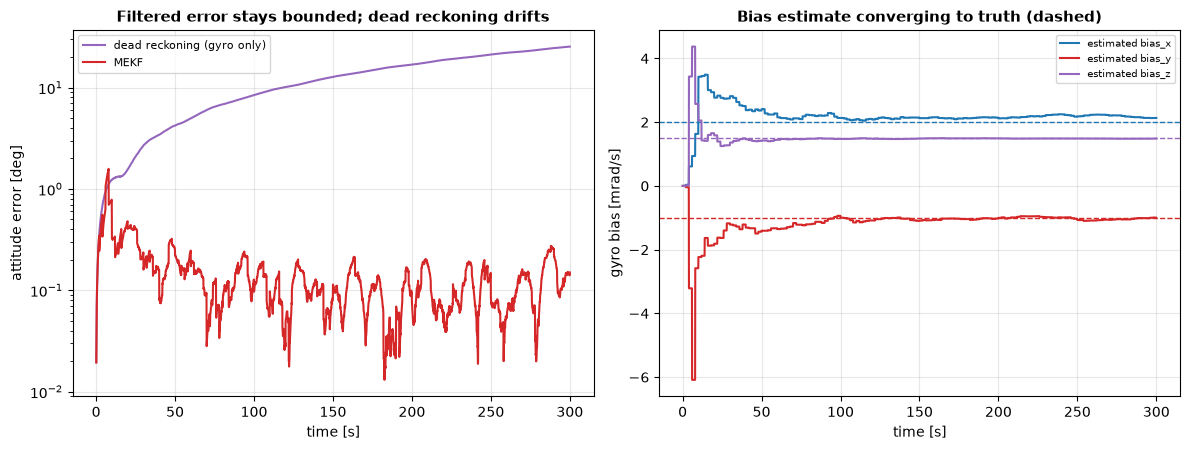

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

axes[0].semilogy(t_eval[1:], err_dead, color=COL_ZONE, label="dead reckoning (gyro only)")
axes[0].semilogy(t_eval[1:], err_filt, color=COL_NUM, label="MEKF")
axes[0].set_xlabel("time [s]")
axes[0].set_ylabel("attitude error [deg]")
axes[0].set_title("Filtered error stays bounded; dead reckoning drifts")
axes[0].legend(fontsize=8)

for i, (label, color) in enumerate(zip(["x", "y", "z"], [COL_ANA, COL_NUM, COL_ZONE])):
    axes[1].plot(t_eval[1:], bias_hist[:, i] * 1e3, color=color, label=f"estimated bias_{label}")
    axes[1].axhline(true_bias[i] * 1e3, color=color, ls="--", lw=1)
axes[1].set_xlabel("time [s]")
axes[1].set_ylabel("gyro bias [mrad/s]")
axes[1].set_title("Bias estimate converging to truth (dashed)")
axes[1].legend(fontsize=7)

fig.tight_layout()

The dead-reckoning error grows essentially without bound, since nothing ever corrects for the gyro's constant bias and that bias integrates directly into a steadily accumulating attitude error. The filtered error, by contrast, stays within a fraction of a degree throughout, bounded by the same measurement noise already characterized in the determination notebook. The bias panel shows why: the filter does not just correct the current attitude at each update, it also learns the gyro's bias from the pattern of corrections needed over time, visibly converging toward the true injected value on all three axes well within the simulated run.

## Summary

This closes the loop the previous two notebooks left open. `rigid_body_attitude_dynamics_symbolic` provides the dynamics; `wahba_svd_attitude` and `triad_attitude` provide the measurements; the MEKF built in `dynamics/attitude/filter.py` ties them together into a single recursive estimator, validated here against the plainest possible failure mode, an uncorrected gyro bias, and shown to handle it while dead reckoning does not.

What stays open at this point: this is still attitude estimation in isolation, with synthetic vector measurements rather than a real sensor model, and a real system would also need to handle intermittent or asynchronous measurements and sensor outages. The pointing requirement that depends on the actual relative geometry to the chief, not on a fixed inertial reference direction, is the subject of the next notebook, and the closed-loop docking simulation later runs this same filter inside a complete guidance, navigation and control chain.